# Notebook 5: Aggregation Functions

Berman's model combines weighted principles into a verdict by a **simple additive
weighted sum**: `F = sum w_i a_i`, decide on the sign of `F`. But that is one choice
among many ways one *could* combine nine weighted principles. This notebook maps
that space and asks two questions: **which combining rules are faithful to Berman,
and what changes if you pick a different one?**

The answer turns on a single, testable property -- whether a rule responds to *how
strongly* each principle is activated, or only to which way it points. That splits
the space into three classes:

| Class | Uses activation magnitudes? | Example | Berman? |
|---|---|---|---|
| **Cardinal (nonlexical)** | yes | the additive sum (SAW) | **faithful** |
| **Ordinal** | no -- only signs/ranks | vote-counting | coherent rival |
| **Lexical** | no -- strict priority | highest-weight principle wins | the **foil** |

### What this notebook establishes
1. The three classes are **operationally real**, separated by one measurement
   (sensitivity to a magnitude-only perturbation): cardinal > 0, ordinal exactly 0,
   lexical ~ 0.
2. Only the **cardinal-nonlexical** class is Berman-faithful -- it is the only one
   that both weighs magnitudes (his 'extent of activation') *and* is nonlexical (not
   the priority rule his theory is defined against).
3. The **headline** Berman called striking: cardinal (SAW) and ordinal (counting)
   aggregation **disagree about real verdicts** on a non-trivial fraction of cases
   (~15% with equal weights, *rising* to ~18% with graded weights), and the
   disagreements are genuine contradictions located where a strongly-activated
   minority outvotes a weakly-activated majority. Continuous activations carry
   verdict-relevant information that ranks throw away.
4. The old paper's two 'impossibility' trade-offs **dissolve** once the lexical
   functions are correctly labelled as the foil (not in-theory options) and the
   'graded weights required' criterion is dropped (Berman permits equal weights).

This is a positive identification and a map, **not** a tournament with a winner: we
are not claiming cardinal *beats* ordinal, only that they *differ*, that the
difference is real, and that one class is the one Berman's theory actually uses.

## Setup

On Colab this mounts your Google Drive and works inside the project folder so the
outputs persist; locally it uses the current folder. The next cell writes the
shared core, then imports it.

In [1]:
import os
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
    "set_determinism", "StrategicSystem",
    "verdict_flip_rates", "system_flip_curve", "principled_tau_percase",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


# ---------------------------------------------------------------------------
# Threshold robustness (NB4): how stable is a verdict under perturbation, and
# what threshold tau would a verdict-robustness criterion recommend?
#
# The criterion is SIGN-robustness: a verdict is robust if its DIRECTION survives
# realistic noise. A threshold tau "protects" determinate verdicts by discarding
# exactly the sign-fragile (near-equipoise) cases -- so robustness rises with tau,
# which means robustness pins a confidence LEVEL, not a unique tau value.
# ---------------------------------------------------------------------------
def verdict_flip_rates(w, A, tau, sigma_w, n_mc=200, seed=0):
    """Per-case flip rate of the gated verdict (sign of F, with |F|<=tau set to 0)
    under weight perturbation w + N(0, sigma_w^2). Returns (v0, |F0|, flip_rate)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    rng = np.random.default_rng(seed)
    F0 = A @ w
    v0 = np.sign(F0); v0[np.abs(F0) <= tau] = 0.0
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v = np.sign(F); v[np.abs(F) <= tau] = 0.0
    flip = np.mean(v != v0[None, :], axis=0)
    return v0, np.abs(F0), flip


def principled_tau_percase(w, A, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """Per-case sustained-crossing read-off. Using SIGN-robustness (does the
    verdict direction survive the noise?), find the smallest |F| cut at and above
    which the (smoothed) robust fraction stays >= P. Returns (tau*, centers, smooth)."""
    _, absF, flip_sign = verdict_flip_rates(w, A, tau=0.0, sigma_w=sigma_w, n_mc=n_mc, seed=seed)
    robust = (flip_sign <= q).astype(float)
    order = np.argsort(absF)
    absF_s, robust_s = absF[order], robust[order]
    window = max(25, len(absF) // 40)
    smooth = np.convolve(robust_s, np.ones(window) / window, mode="valid")
    centers = absF_s[window // 2: window // 2 + len(smooth)]
    ok = smooth >= P
    sustained = ok & np.cumprod(ok[::-1])[::-1].astype(bool)    # >= P from here up
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return (float(centers[idx]) if idx is not None else float("nan")), centers, smooth


def system_flip_curve(w, A, tau_grid, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """System sign-robust fraction over a tau grid. For each tau, among cases the
    model calls determinate (|F0|>tau), the fraction whose SIGN is robust (sign-flip
    rate <= q) under weight noise. tau* = smallest tau where it reaches and stays >=P.
    Returns (tau_grid, robust_fraction, n_determinate, tau*)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    F0 = A @ w; absF0 = np.abs(F0)
    rng = np.random.default_rng(seed)
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v_sign = np.sign(F)
    robust_frac = np.full(len(tau_grid), np.nan); n_det = np.zeros(len(tau_grid))
    for i, tau in enumerate(tau_grid):
        v0 = np.sign(F0); v0[absF0 <= tau] = 0.0
        det = v0 != 0; n_det[i] = det.sum()
        if det.sum() == 0:
            continue
        flip = np.mean(v_sign[:, det] != v0[None, det], axis=0)
        robust_frac[i] = float(np.mean(flip <= q))
    valid = ~np.isnan(robust_frac); okv = (robust_frac >= P) & valid
    sustained = np.zeros(len(tau_grid), bool); run = True
    for j in range(len(tau_grid) - 1, -1, -1):
        if not valid[j]:
            continue
        run = run and okv[j]; sustained[j] = run
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return tau_grid, robust_frac, n_det, (float(tau_grid[idx]) if idx is not None else float("nan"))


# ---------------------------------------------------------------------------
# Mechanism 3: STRATEGIC LEARNING (multi-agent reinforcement learning)
#
# The third candidate model of "the practice that confers the weights." Judges
# are reward-optimising agents: each has a context-sensitive INVOCATION policy
# (a small shared net plus a per-judge methodology lean) and the bench shares one
# context-free WEIGHT head. The learned weight multiplies activations inside each
# judge's SAW force, so optimisation moves a genuine SAW weight -- not an
# invocation count (the bug in the original paper's MARL).
#
# This is the LEAST Bermanian of the three mechanisms: Berman never describes
# judges optimising a goal. It is a robustness probe, not an interpretation of
# Berman. Reliance (RelianceSystem) is the closest to his account; uptake
# (LegalSystem) is a simplification; this is a third lens.
# ---------------------------------------------------------------------------
def set_determinism(seed: int):
    """Make a torch run reproducible and return a seeded generator to thread
    through every random draw (so sampling never touches the global stream)."""
    import torch
    torch.manual_seed(seed)
    np.random.seed(seed)
    try:
        torch.use_deterministic_algorithms(True)
    except Exception:
        pass
    torch.set_num_threads(1)                 # 1 thread => deterministic + fast enough (tiny net)
    g = torch.Generator()
    g.manual_seed(seed)
    return g


class StrategicSystem:
    """Judges as reward-optimising RL agents; the learned WEIGHT head is read out
    as the emergent SAW weight vector.

    Key design points (see module header):
      * The weight enters the force the reward optimises:
            F_i = sum_p invoked_{i,p} * w_p * a_p,   w = sigmoid(weight_logit).
      * The per-principle contribution is a *stochastic* Normal node, so the
        REINFORCE log-prob carries gradient into the weight head. Without this the
        weight only sits in a detached scalar reward and never moves (stays frozen).
      * Reward = consensus agreement routed through the SAW force, with
        decisiveness GATED ON AGREEMENT, minus a parsimony penalty -- which kills
        the degenerate "invoke everything" optimum.
      * Learning rate anneals linearly to 0 (anneal=True), which gives a stable,
        reproducible read-out at the end of training. NOTE: the flat tail is partly
        a consequence of the annealing schedule, not by itself proof that a unique
        fixed point was reached -- the weight is read from the settled region the
        optimiser occupies. Set anneal=False to hold the rate and inspect the
        un-frozen process (the scalar weight keeps wandering; the structural
        *pattern* is stable -- the notebook demonstrates this).

    The readout is the continuous learned weight (normalised to max=1), NOT a
    thresholded invocation frequency (which would merely reproduce LegalSystem
    uptake). It plugs straight into net_force / saw_verdict / critical_sigma.
    Because the weight gradient is gated by invocation, the learned structure stays
    correlated with how often principles are invoked -- the readout is a different
    *quantity* from uptake, not an uncorrelated one.
    """

    def __init__(self, n_agents=24, panel_size=9, n_episodes=6000, lr_inv=5e-3,
                 sigma=0.08, parsimony=0.08, decisive_bonus=0.5, activations="correlated",
                 neutral_init=False, null_reward=False, anneal=True, tau=DEFAULT_TAU,
                 checkpoint=200, seed=0):
        import torch
        import torch.nn as nn
        assert panel_size % 2 == 1, "panel_size must be odd so the majority sign is never a tie"
        self.g = set_determinism(seed)
        n_p = len(NAMED_PRINCIPLES)
        self.n_p, self.n_agents, self.panel_size = n_p, n_agents, panel_size
        self.n_episodes, self.lr_inv, self.checkpoint = n_episodes, lr_inv, checkpoint
        self.sigma, self.parsimony, self.decisive_bonus = sigma, parsimony, decisive_bonus
        self.activations, self.tau, self.seed = activations, tau, seed
        self.null_reward = null_reward      # ablation: replace the reward with a constant (no signal)
        self.anneal = anneal                # anneal LR to 0 (stable read-out) vs hold it (inspect the process)
        # numpy streams for cases and panels (the NB1/NB2 SeedSequence pattern)
        ss = np.random.SeedSequence(seed)
        self._rng_cases, self._rng_panels = (np.random.default_rng(s) for s in ss.spawn(2))
        # invocation policy: one shared body + a per-judge bias (methodology lean)
        self.net = nn.Sequential(nn.Linear(n_p, 32), nn.ReLU(), nn.Linear(32, n_p))
        bias = np.zeros((n_agents, n_p))
        if not neutral_init:                                   # shared start with LegalSystem/RelianceSystem
            for i in range(n_agents):
                t = methodology_tendencies(METHODOLOGIES[i % 4], "wide",
                                           np.random.default_rng(seed * 1000 + i))
                t = np.clip(t, 1e-3, 1 - 1e-3)
                bias[i] = np.log(t / (1 - t))                  # tendencies -> logit space
        self.bias = nn.Parameter(torch.tensor(bias, dtype=torch.float32))
        wl = torch.empty(n_p)
        nn.init.normal_(wl, 0.0, 0.30)                         # weight head not degenerate-uniform at init
        self.weight_logit = nn.Parameter(wl)
        self.init_weight = torch.sigmoid(wl).detach().numpy().copy()
        self.weight_history = []   # readout() every `checkpoint` episodes (convergence)
        self.reward_history = []   # EMA reward at each checkpoint (training curve)
        self.delta_history = []    # mean|W(t)-W(t-1)| between checkpoints
        self._trained = False

    def readout(self):
        """The emergent SAW weight: continuous learned weight normalised to max=1."""
        import torch
        w = torch.sigmoid(self.weight_logit).detach().numpy()
        m = w.max()
        return w / m if m > 0 else w

    def train(self):
        import math
        import torch
        opt = torch.optim.Adam([
            {"params": list(self.net.parameters()) + [self.bias], "lr": self.lr_inv},
            {"params": [self.weight_logit], "lr": 4 * self.lr_inv},   # weaker Gaussian gradient -> higher LR
        ])
        init_lrs = [self.lr_inv, 4 * self.lr_inv]
        logconst = math.log(self.sigma * math.sqrt(2 * math.pi))
        baseline = 0.0
        A = (category_correlated_activations(self.n_episodes, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(self.n_episodes, self.n_p, self._rng_cases))
        panels = np.array([self._rng_panels.choice(self.n_agents, self.panel_size, replace=False)
                           for _ in range(self.n_episodes)])
        for ep in range(self.n_episodes):
            frac = (1.0 - ep / self.n_episodes) if self.anneal else 1.0   # anneal to 0, or hold the rate
            for grp, il in zip(opt.param_groups, init_lrs):
                grp["lr"] = il * frac
            a = torch.tensor(A[ep], dtype=torch.float32)
            logits = self.net(a)[None, :] + self.bias[panels[ep]]      # (P, n_p): context + per-judge lean
            p = torch.sigmoid(logits)
            invoked = torch.bernoulli(p, generator=self.g)
            log_prob_inv = (invoked * torch.log(p + 1e-8)
                            + (1 - invoked) * torch.log(1 - p + 1e-8)).sum(1)
            w = torch.sigmoid(self.weight_logit)
            mean_c = invoked * w[None, :] * a[None, :]                 # SAW contribution; carries w-gradient
            eps = torch.randn(mean_c.shape, generator=self.g)
            c = (mean_c + self.sigma * eps).detach()                  # sampled action (detached)
            log_prob_w = (-0.5 * ((c - mean_c) / self.sigma) ** 2 - logconst).sum(1)
            F = c.sum(1)                                               # judge force = genuine weighted SAW sum
            maj = torch.sign(torch.sign(F).sum())                     # panel-majority verdict sign
            agreed = (torch.sign(F) == maj).float()
            decisive = (F.abs() > self.tau).float()
            if self.null_reward:
                reward = torch.ones(self.panel_size)          # ablation: no learning signal -> weight goes uniform
            else:
                reward = (agreed + self.decisive_bonus * decisive * agreed
                          - self.parsimony * (invoked.sum(1) / self.n_p))
            adv = (reward - baseline).detach()                        # baseline = variance-reducing EMA
            baseline = 0.99 * baseline + 0.01 * float(reward.mean())
            loss = -((log_prob_inv + log_prob_w) * adv).mean() + 1e-3 * (self.weight_logit ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if (ep + 1) % self.checkpoint == 0:
                r = self.readout()
                if self.weight_history:
                    self.delta_history.append(float(np.abs(r - self.weight_history[-1]).mean()))
                self.weight_history.append(r)
                self.reward_history.append(float(baseline))
        self._trained = True
        return self.readout()

    def converged(self, window=5, tol=0.01):
        """True if the readout has plateaued: mean of the last `window`
        between-checkpoint deltas is below `tol`."""
        if len(self.delta_history) < window:
            return False
        return float(np.mean(self.delta_history[-window:])) < tol

    @property
    def delta_last(self):
        return self.delta_history[-1] if self.delta_history else float("nan")

    def moved_from_init(self):
        """Mean absolute change of the (normalised) weight from its init -- a check
        that the weight head actually trained rather than staying frozen."""
        init_norm = self.init_weight / max(self.init_weight.max(), 1e-9)
        return float(np.abs(self.readout() - init_norm).mean())


if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from berman_core import *
OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data/notebook5'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
PN = [p for p,_ in NAMED_PRINCIPLES]; CAT = [c for _,c in NAMED_PRINCIPLES]; n_p=len(PN)
TIER_OF = np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])
summary = {}
print('ready; outputs ->', os.path.abspath(OUTDIR))

ready; outputs -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/data/notebook5


## The ten aggregation functions

Each function takes weights `w` and an activation matrix `A` (one row per case) and
returns a verdict in {-1, 0, +1} per case. Three reuse the shared core; the rest
are short helpers. They span the three classes, with several cardinal variants so
we can prove the real divide is cardinal-vs-*ordinal*, not an artifact of a gate or
a normalization choice.

- **Cardinal-nonlexical** (Berman's class): `SAW` (the model, gated at tau=0.2);
  `SAW-sign` (Berman's bare sign rule, no gate -- the clean cardinal reference);
  `SAW-L1` (weights re-normalized -- trivially sign-identical to SAW-sign, since a
  positive rescale can't change a sign; included only to forestall the
  normalization objection); `Nonlinear` (magnitude-*emphasizing*).
- **Ordinal**: `vote-count`; `weighted-vote` (keeps weights, drops magnitudes);
  `Borda` (rank-based); `median-sign` (which equals vote-count for an odd panel --
  a coincidence, not an independent rule).
- **Lexical (the foil)**: `lexicographic` (highest-weight active principle wins);
  `cascade` (the highest-priority active *principle*, by category then weight,
  decides -- lower-priority principles never consulted).

In [4]:
def f_saw(w, A):      return saw_verdict(w, A, tau=0.2)
def f_saw_sign(w, A): return np.sign(A @ w).astype(int)            # Berman's bare rule (no gate)
def f_saw_l1(w, A):   return np.sign(A @ (w/np.sum(w))).astype(int)
def f_nonlinear(w, A, beta=4.0):
    return np.sign(((w[None,:]*A)*np.exp(beta*np.abs(A))).sum(1)).astype(int)
def f_vote(w, A):     return np.sign(np.sign(A).sum(1)).astype(int)
def f_wvote(w, A):    return np.sign((w[None,:]*np.sign(A)).sum(1)).astype(int)
def f_borda(w, A):
    ow = ordinalize(w)                                            # ordinal weights
    ranks = np.argsort(np.argsort(np.abs(A), axis=1), axis=1) + 1 # rank of |a| per case
    s = (ow[None,:]*np.sign(A)*ranks).sum(1)
    return np.where(np.abs(s) < 1e-9, 0, np.sign(s)).astype(int)   # explicit tie -> 0 (no float-order dep)
def f_median(w, A):   return np.sign(np.median(np.sign(A), axis=1)).astype(int)
def f_lex(w, A):      return lexicographic_verdict(w, A)
def f_cascade(w, A):                                             # purely lexical: top-priority active principle
    A = np.asarray(A); pri = np.lexsort((-w, TIER_OF))           # priority order: tier asc, then weight desc
    Ap = A[:, pri]; active = np.abs(Ap) > 1e-9
    first = np.argmax(active, axis=1)                            # first active principle in priority order
    v = np.sign(Ap[np.arange(len(A)), first]).astype(int); v[~active.any(axis=1)] = 0
    return v
FUNCTIONS = [
    ('SAW (tau=0.2)', f_saw, 'cardinal', True), ('SAW-sign', f_saw_sign, 'cardinal', True),
    ('SAW-L1', f_saw_l1, 'cardinal', True), ('Nonlinear', f_nonlinear, 'cardinal', True),
    ('vote-count', f_vote, 'ordinal', True), ('weighted-vote', f_wvote, 'ordinal', True),
    ('Borda', f_borda, 'ordinal', True), ('median-sign', f_median, 'ordinal', True),
    ('lexicographic', f_lex, 'lexical(FOIL)', False), ('cascade', f_cascade, 'lexical(FOIL)', False)]
def make_activations(kind, n, rng):
    if kind=='independent': return random_activations(n, n_p, rng)
    if kind=='category':    return category_correlated_activations(n, rng, rho=0.7)
    if kind=='fully':       return fully_correlated_activations(n, n_p, rng)
print('defined', len(FUNCTIONS), 'functions')

defined 10 functions


## Experiment 0 -- The three classes are operationally real

The classification is not just a label. We probe each function with a perturbation
that changes activation *magnitudes* while preserving every sign and rank
(`nonlexicality_score`). A function that responds is cardinal; one that doesn't is
ordinal (it never saw the magnitudes) or lexical (it only used a priority order).
One caveat: the ordinal `= 0` holds *by construction* -- the probe perturbs only the
magnitudes that ordinal rules ignore, so they cannot move. The empirical content is
on the cardinal side: magnitudes genuinely change those verdicts (`> 0`).

In [5]:
w = named_weight_vector('moderate', seed=0); A = random_activations(3000, n_p, np.random.default_rng(1))
rows = [dict(function=nm, family=fam, nonlexicality=nonlexicality_score(lambda X, fn=fn: fn(w, X), A, seed=2))
        for nm, fn, fam, _ in FUNCTIONS]
df0 = pd.DataFrame(rows); df0.to_csv(f'{OUTDIR}/nb5_nonlexicality.csv', index=False)
print(df0.to_string(index=False))
card = df0[df0.family=='cardinal'].nonlexicality; ordi = df0[df0.family=='ordinal'].nonlexicality
summary['exp0'] = dict(cardinal_min=float(card.min()), ordinal_max=float(ordi.max()),
                       lexical_max=float(df0[df0.family.str.startswith('lexical')].nonlexicality.max()))
print(f"\ncardinal all > 0 (min {card.min():.3f}); ordinal all = 0 (max {ordi.max():.4f})")

     function        family  nonlexicality
SAW (tau=0.2)      cardinal       0.049615
     SAW-sign      cardinal       0.022948
       SAW-L1      cardinal       0.022948
    Nonlinear      cardinal       0.074938
   vote-count       ordinal       0.000000
weighted-vote       ordinal       0.000000
        Borda       ordinal       0.000000
  median-sign       ordinal       0.000000
lexicographic lexical(FOIL)       0.002354
      cascade lexical(FOIL)       0.000000

cardinal all > 0 (min 0.023); ordinal all = 0 (max 0.0000)


## Experiment 0b - Does the class separation survive the whole grid?

Experiment 0 measures the magnitude probe at ONE configuration: moderate weights
at seed 0, three thousand cases, independent activations. That is enough to
report the scores, and it is what Figure 5 draws, but it cannot tell us whether
the cardinal/ordinal separation is a fact about the rules or an artifact of that
configuration.

This runs the same probe across the full grid Experiment 1 uses: three weight
regimes by three activation regimes, thirty seeds each. The question is whether
the cardinal family stays above the non-cardinal ceiling in every cell.


In [6]:
rows = []
for wr in ['equal', 'moderate', 'high']:
    for ak in ['independent', 'category', 'fully']:
        acc = {}
        for s in range(30):
            rng = np.random.default_rng(9000 + s)
            wv  = np.ones(n_p) if wr == 'equal' else named_weight_vector(wr, seed=s)
            A   = make_activations(ak, 3000, rng)
            for nm, fn, fam, _ in FUNCTIONS:
                acc.setdefault((nm, fam), []).append(
                    nonlexicality_score(lambda X, fn=fn, wv=wv: fn(wv, X), A, seed=2))
        for (nm, fam), v in acc.items():
            rows.append(dict(weights=wr, activations=ak, function=nm, family=fam,
                             nonlexicality=float(np.mean(v)), sd=float(np.std(v))))

dfg = pd.DataFrame(rows)
dfg.to_csv(f'{OUTDIR}/nb5_nonlexicality_grid.csv', index=False)

sep = []
for (wr, ak), grp in dfg.groupby(['weights', 'activations']):
    cmin = float(grp[grp.family == 'cardinal'].nonlexicality.min())
    omax = float(grp[grp.family != 'cardinal'].nonlexicality.max())
    sep.append(dict(weights=wr, activations=ak, cardinal_min=cmin,
                    noncardinal_max=omax, ratio=cmin / omax if omax > 0 else float('inf'),
                    separated=bool(cmin > omax)))
dfs = pd.DataFrame(sep)
print(dfs.round(4).to_string(index=False))

by_act = dfs.groupby('activations').ratio.agg(['min', 'max'])
summary['exp0b'] = {
    'n_configurations': int(len(dfs)),
    'separated_in': int(dfs.separated.sum()),
    'ratio_by_activation': {k: [float(r['min']), float(r['max'])] for k, r in by_act.iterrows()},
    'fails_under': sorted(dfs[~dfs.separated].activations.unique().tolist()),
}
print(f"\nseparation holds in {int(dfs.separated.sum())} of {len(dfs)} configurations")
print("ratio by activation regime (min, max across weight regimes):")
for k, r in by_act.iterrows():
    print(f"  {k:12s} {r['min']:.1f}x to {r['max']:.1f}x")
print("\n-> the weight distribution is idle: the probe barely moves across equal/moderate/high.")
print("-> the ACTIVATION structure is not idle. Under full correlation every principle fires")
print("   together, so a magnitude-only perturbation has almost nothing left to move, and the")
print("   cardinal family falls to the lexical foil's level. The separation is a fact about")
print("   the rules only where the cases still contain conflict.")

assert dfs[dfs.activations == 'independent'].separated.all(), 'must separate on independent activations'
assert dfs[dfs.activations == 'category'].separated.all(), 'must separate on category-correlated activations'


 weights activations  cardinal_min  noncardinal_max  ratio  separated
   equal    category        0.0148           0.0034 4.4210       True
   equal       fully        0.0030           0.0035 0.8616      False
   equal independent        0.0257           0.0027 9.5766       True
    high    category        0.0146           0.0036 4.0517       True
    high       fully        0.0033           0.0033 0.9714      False
    high independent        0.0259           0.0026 9.8007       True
moderate    category        0.0146           0.0036 4.0682       True
moderate       fully        0.0030           0.0033 0.9088      False
moderate independent        0.0258           0.0026 9.7376       True

separation holds in 6 of 9 configurations
ratio by activation regime (min, max across weight regimes):
  category     4.1x to 4.4x
  fully        0.9x to 1.0x
  independent  9.6x to 9.8x

-> the weight distribution is idle: the probe barely moves across equal/moderate/high.
-> the ACTIVATION struct

*Reading.* The separation is robust to how the weights are distributed and
fragile to how the activations are structured. It holds by roughly ten to one on
independent activations and four to one under category correlation, which is the
range the Article treats as realistic. Under FULL correlation it disappears: the
cardinal minimum falls to the lexical foil's level. That is not a defect in the
rules but a property of the cases, since when every principle fires together
there is almost no magnitude-only variation left for the probe to find.


## Experiment 1 -- The cardinal-vs-ordinal disagreement (the headline)

Berman called this contrast 'striking.' We make it precise. The cardinal reference
is `SAW-sign` (Berman's bare sign rule, no threshold -- so the comparison is purely
cardinal-vs-ordinal, not contaminated by a gate). We measure how often it disagrees
with each ordinal rule, across three weight regimes (equal / moderate / high) and
three activation structures (independent / category-correlated / fully-correlated).
`opposite-side` counts only the strong form: both rules decide, and they pick
*contradictory* winners.

In [7]:
def disagree(vc, vo):
    full = float(np.mean(vc != vo))
    both = (vc != 0) & (vo != 0)
    opp = float(np.mean(vc[both] != vo[both])) if both.any() else 0.0
    return full, opp
ord_rules = [('vote-count', f_vote), ('weighted-vote', f_wvote), ('Borda', f_borda)]
rows = []
for wr in ['equal','moderate','high']:
    for ak in ['independent','category','fully']:
        for onm, ofn in ord_rules:
            fulls = []; opps = []
            for s in range(30):
                rng = np.random.default_rng(7000+s)
                wv = np.ones(n_p) if wr=='equal' else named_weight_vector(wr, seed=s)
                A = make_activations(ak, 4000, rng)
                f, o = disagree(f_saw_sign(wv, A), ofn(wv, A)); fulls.append(f); opps.append(o)
            rows.append(dict(weights=wr, activations=ak, ordinal=onm,
                             disagree_full=float(np.mean(fulls)), opposite_side=float(np.mean(opps))))
grid = pd.DataFrame(rows); grid.to_csv(f'{OUTDIR}/nb5_disagreement_grid.csv', index=False)
anchor = grid[(grid.weights=='equal')&(grid.activations=='independent')&(grid.ordinal=='vote-count')].disagree_full.iloc[0]
vc = grid[grid.ordinal=='vote-count']
print(f'NB7-T5 anchor (equal/independent/vote-count): {anchor:.4f}  (T5 reported ~0.153)')
print('vote-count disagreement with SAW, by weight x activation:')
print(vc.pivot(index='weights', columns='activations', values='disagree_full').round(3).to_string())
summary['exp1'] = dict(anchor=float(anchor),
    equal_indep=float(vc[(vc.weights=='equal')&(vc.activations=='independent')].disagree_full.iloc[0]),
    high_indep=float(vc[(vc.weights=='high')&(vc.activations=='independent')].disagree_full.iloc[0]),
    fully=float(vc[(vc.weights=='moderate')&(vc.activations=='fully')].disagree_full.iloc[0]))
print(f"\nrises with weights (equal {summary['exp1']['equal_indep']:.3f} -> high {summary['exp1']['high_indep']:.3f}); "
      f"falls with correlation (fully {summary['exp1']['fully']:.3f})")
# honesty: the rise is specific to the COUNTING rules. Borda (rank-based) moves the OTHER way.
borda = grid[grid.ordinal=='Borda']
b_eq = borda[(borda.weights=='equal')&(borda.activations=='independent')].disagree_full.iloc[0]
b_hi = borda[(borda.weights=='high')&(borda.activations=='independent')].disagree_full.iloc[0]
print(f'(Borda, being rank-based, FALLS as weights spread: equal {b_eq:.3f} -> high {b_hi:.3f}, because ranking discards the cardinal spread.)')
summary['exp1']['borda_equal']=float(b_eq); summary['exp1']['borda_high']=float(b_hi)

NB7-T5 anchor (equal/independent/vote-count): 0.1533  (T5 reported ~0.153)
vote-count disagreement with SAW, by weight x activation:
activations  category  fully  independent
weights                                  
equal           0.115  0.029        0.153
high            0.122  0.031        0.178
moderate        0.117  0.029        0.158

rises with weights (equal 0.153 -> high 0.178); falls with correlation (fully 0.029)
(Borda, being rank-based, FALLS as weights spread: equal 0.165 -> high 0.090, because ranking discards the cardinal spread.)


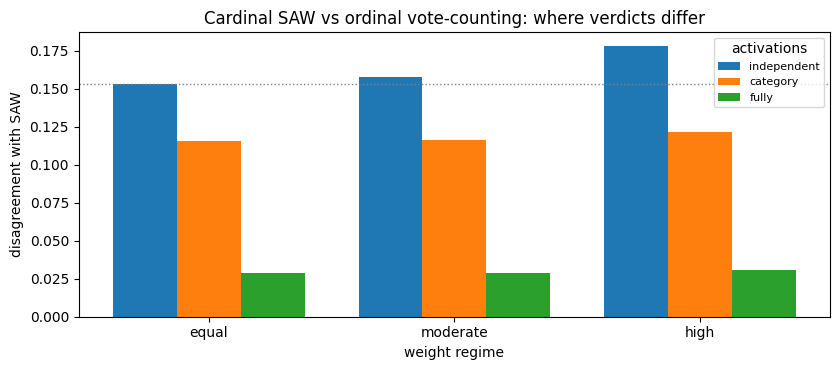

In [8]:
fig, ax = plt.subplots(figsize=(8.5,3.8)); xx=np.arange(3); ww=0.26
for i,ak in enumerate(['independent','category','fully']):
    sub=vc[vc.activations==ak].set_index('weights').loc[['equal','moderate','high']]
    ax.bar(xx+(i-1)*ww, sub.disagree_full, ww, label=ak)
ax.axhline(anchor, color='grey', ls=':', lw=1)
ax.set_xticks(xx); ax.set_xticklabels(['equal','moderate','high'])
ax.set(xlabel='weight regime', ylabel='disagreement with SAW', title='Cardinal SAW vs ordinal vote-counting: where verdicts differ')
ax.legend(title='activations', fontsize=8); plt.tight_layout()
plt.savefig(f'{FIGDIR}/nb5_cardinal_ordinal.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 2 -- Where the disagreement lives

Why do they diverge? We profile the cases where SAW and vote-counting disagree. The
prediction: disagreements cluster at **small net force** (close calls) and at
**mixed-magnitude** cases -- a few strongly-activated principles on one side
outvoting a numerical majority of weakly-activated ones on the other. That is
exactly the information ordinal rules discard.

mean |F|: disagreeing 0.35 vs agreeing 1.03
minority-magnitude-mass: disagreeing 0.44 vs agreeing 0.32
disagree rate, smallest-|F| decile 0.40 -> largest 0.00


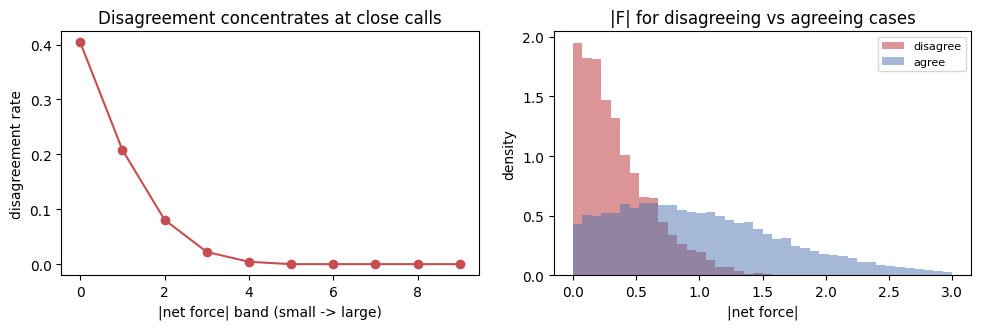

In [9]:
rng = np.random.default_rng(12345); w = named_weight_vector('moderate', seed=0)
A = random_activations(20000, n_p, rng); F = A @ w
dis = f_saw_sign(w, A) != f_vote(w, A)
absF = np.abs(F)
# minority-magnitude-mass: share of total |w*a| held by the side that LOSES the vote count
contrib = w[None,:]*A; pos = np.where(contrib>0, contrib, 0).sum(1); neg = np.where(contrib<0,-contrib,0).sum(1)
minority_mass = np.minimum(pos,neg)/(pos+neg+1e-12)
deciles = np.clip((absF/np.quantile(absF,0.999)*10).astype(int),0,9)
drate = [float(dis[deciles==d].mean()) if (deciles==d).any() else np.nan for d in range(10)]
prof = pd.DataFrame({'decile':range(10),'disagree_rate':drate}); prof.to_csv(f'{OUTDIR}/nb5_when_diverge.csv', index=False)
print(f'mean |F|: disagreeing {absF[dis].mean():.2f} vs agreeing {absF[~dis].mean():.2f}')
print(f'minority-magnitude-mass: disagreeing {minority_mass[dis].mean():.2f} vs agreeing {minority_mass[~dis].mean():.2f}')
print(f'disagree rate, smallest-|F| decile {drate[0]:.2f} -> largest {drate[-1]:.2f}')
summary['exp2'] = dict(meanF_disagree=float(absF[dis].mean()), meanF_agree=float(absF[~dis].mean()),
                       minmass_disagree=float(minority_mass[dis].mean()), minmass_agree=float(minority_mass[~dis].mean()),
                       drate_small=float(drate[0]), drate_large=float(drate[-1]))
fig, ax = plt.subplots(1,2, figsize=(10,3.4))
ax[0].plot(range(10), drate, 'o-', color='#C44E52'); ax[0].set(xlabel='|net force| band (small -> large)', ylabel='disagreement rate', title='Disagreement concentrates at close calls')
ax[1].hist(absF[dis], bins=40, range=(0,3), alpha=.6, density=True, label='disagree', color='#C44E52')
ax[1].hist(absF[~dis], bins=40, range=(0,3), alpha=.5, density=True, label='agree', color='#4C72B0')
ax[1].set(xlabel='|net force|', ylabel='density', title='|F| for disagreeing vs agreeing cases'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb5_when_diverge.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 3 -- The full taxonomy battery

Every function, scored on determinacy (each gated at its own natural cutoff),
nonlexicality, and agreement with SAW. The point is the *pattern by family*, not a
ranking. A crucial honesty note: **every ungated rule** -- the lexical foils, the
ordinal rules, and even bare SAW-sign -- shows determinacy ~1.0 and a large 'Hart
margin'. That is not an advantage of any of them; it is purely the absence of the
tau gate, the **equipoise-discarding artifact** the audit diagnoses (they never sit
in the close-call band). Only the gated SAW(tau=0.2) is below ~1.0. We report it so
the inflated determinacy can't be mistaken for a win over the Berman reference.

In [10]:
rows=[]
for nm, fn, fam, in_th in FUNCTIONS:
    det=[]; nlx=[]; agr=[]
    for s in range(20):
        rng=np.random.default_rng(8000+s); w=named_weight_vector('moderate', seed=s); A=random_activations(3000,n_p,rng)
        v=fn(w,A); vsaw=saw_verdict(w,A,tau=0.2)
        det.append(np.mean(v!=0)); nlx.append(nonlexicality_score(lambda X,fn=fn: fn(w,X), A, seed=s))
        agr.append(np.mean(v==vsaw))
    rows.append(dict(function=nm, family=fam, in_theory=in_th, determinacy=np.mean(det),
                     nonlexicality=np.mean(nlx), agree_with_SAW=np.mean(agr)))
bat=pd.DataFrame(rows); bat.to_csv(f'{OUTDIR}/nb5_taxonomy_battery.csv', index=False)
print(bat.round(3).to_string(index=False))
summary['exp3'] = dict(ordinal_nonlex_max=float(bat[bat.family=='ordinal'].nonlexicality.max()),
                       foil_determinacy=float(bat[~bat.in_theory].determinacy.mean()),
                       saw_determinacy=float(bat[bat.function=='SAW (tau=0.2)'].determinacy.iloc[0]))

     function        family  in_theory  determinacy  nonlexicality  agree_with_SAW
SAW (tau=0.2)      cardinal       True        0.863          0.051           1.000
     SAW-sign      cardinal       True        1.000          0.026           0.863
       SAW-L1      cardinal       True        1.000          0.026           0.863
    Nonlinear      cardinal       True        1.000          0.075           0.761
   vote-count       ordinal       True        1.000          0.000           0.765
weighted-vote       ordinal       True        1.000          0.000           0.765
        Borda       ordinal       True        0.996          0.000           0.795
  median-sign       ordinal       True        1.000          0.000           0.765
lexicographic lexical(FOIL)      False        1.000          0.002           0.577
      cascade lexical(FOIL)      False        1.000          0.000           0.561


## Experiment 4 -- SAW's reference numbers

The Berman-faithful rule's own R4 (Hart margin) and R2 (rough-weight tolerance), so
the foils' inflated determinacy can be read against the right baseline.

In [11]:
margins=[]; sigmas=[]
for s in range(20):
    rng=np.random.default_rng(8100+s); w=named_weight_vector('moderate', seed=s); A=random_activations(3000,n_p,rng)
    margins.append(hart_advantage(w, A, TIER_OF)); sigmas.append(critical_sigma(w, A, n_mc=48, seed=s))
summary['exp4'] = dict(hart_margin=float(np.mean(margins)), critical_sigma=float(np.mean(sigmas)))
print(f"SAW Hart margin (R4) = {np.mean(margins):+.3f}; critical_sigma (R2) = {np.mean(sigmas):.3f}")
print('(every UNGATED rule shows determinacy ~1.0 -- the equipoise-discarding artifact -- not a win over this gated reference)')

SAW Hart margin (R4) = +0.268; critical_sigma (R2) = 0.066
(every UNGATED rule shows determinacy ~1.0 -- the equipoise-discarding artifact -- not a win over this gated reference)


## Self-check

The taxonomy (cardinal>0, ordinal exactly 0, lexical~0), the headline numbers
(reproducing NB7 T5 and rising with graded weights), the mechanism (close calls),
and REF guards.

## E2b: where the disagreements sit, and agreement on decided cases

Part VII prints a closeness profile in **equal-count deciles** of the caseload, while E2 above saves
**equal-width bands** of net force. Both are legitimate; this cell saves the one the manuscript
prints, plus the closeness statistics and the verdict-agreement figures restricted to the cases the
gated weighted sum actually decides.

In [12]:
# --- E2b: closeness profile (equal-count deciles) + restricted verdict agreement ---
rng_c = np.random.default_rng(12345); w_c = named_weight_vector('moderate', seed=0)
A_c   = random_activations(20000, n_p, rng_c); F_c = A_c @ w_c; absF_c = np.abs(F_c)
dis_c = f_saw_sign(w_c, A_c) != f_vote(w_c, A_c)

# equal-COUNT deciles of |net force|, closest tenth first
q   = np.quantile(absF_c, np.linspace(0, 1, 11))
dec = np.clip(np.searchsorted(q, absF_c, side='right') - 1, 0, 9)
drate_count = [float(dis_c[dec == d].mean()) for d in range(10)]
pd.DataFrame({'decile': range(1, 11), 'disagree_rate': drate_count}).to_csv(
    f'{OUTDIR}/nb5_closeness_deciles.csv', index=False)

half = absF_c <= np.median(absF_c)
closeness = dict(
    overall_rate         = float(dis_c.mean()),
    rate_closer_half     = float(dis_c[half].mean()),
    rate_farther_half    = float(dis_c[~half].mean()),
    share_in_closer      = float(dis_c[half].sum() / dis_c.sum()),
    max_absF_disagree    = float(absF_c[dis_c].max()),
    max_absF_observed    = float(absF_c.max()),
    share_above_1p5      = float((absF_c > 1.5).mean()),
    n_disagree_above_1p5 = int(dis_c[absF_c > 1.5].sum()))

# verdict agreement RESTRICTED to the cases the gated weighted sum decides.
# The gated reference is excluded: no ungated rule can exceed its own determinacy on the raw measure.
saw_det = float(bat.loc[bat.function == 'SAW (tau=0.2)', 'determinacy'].iloc[0])
restricted = {r.function: float(r.agree_with_SAW / saw_det)
              for _, r in bat.iterrows() if r.function != 'SAW (tau=0.2)'}
pd.DataFrame([dict(function=k, agree_restricted=v) for k, v in restricted.items()]).to_csv(
    f'{OUTDIR}/nb5_agreement_restricted.csv', index=False)

summary['exp2b'] = dict(closeness, deciles_equalcount=drate_count,
                        saw_determinacy=saw_det, agree_restricted=restricted)
print('equal-count deciles (closest first):', [round(x, 3) for x in drate_count])
print(f"closer half {closeness['rate_closer_half']:.3f} vs farther {closeness['rate_farther_half']:.3f}; "
      f"{closeness['share_in_closer']:.3f} of disagreements sit in the closer half")
print(f"largest |F| on a disagreement {closeness['max_absF_disagree']:.2f} "
      f"against an observed maximum of {closeness['max_absF_observed']:.2f}")
print('restricted agreement:', {k: round(v, 3) for k, v in restricted.items()})


equal-count deciles (closest first): [0.449, 0.39, 0.302, 0.204, 0.152, 0.08, 0.048, 0.015, 0.003, 0.0]
closer half 0.299 vs farther 0.029; 0.911 of disagreements sit in the closer half
largest |F| on a disagreement 1.61 against an observed maximum of 4.44
restricted agreement: {'SAW-sign': 1.0, 'SAW-L1': 1.0, 'Nonlinear': 0.881, 'vote-count': 0.886, 'weighted-vote': 0.886, 'Borda': 0.921, 'median-sign': 0.886, 'lexicographic': 0.668, 'cascade': 0.65}


In [13]:
REF = dict(anchor=0.153, equal_indep=0.153, high_indep=0.178, hart_margin=0.27)
ok = True
def check(name, cond):
    global ok; ok = ok and bool(cond); print(('PASS' if cond else 'FAIL') + ' - ' + name)

# E0 taxonomy is operationally real
check('cardinal functions all magnitude-sensitive (nonlex > 0)', summary['exp0']['cardinal_min'] > 0.0)
check('ordinal functions exactly magnitude-blind (nonlex == 0)', summary['exp0']['ordinal_max'] == 0.0)
check('lexical foil ~ 0 (sees only priority)', summary['exp0']['lexical_max'] < 0.02)
# E1 headline
check('reproduces NB7 T5 anchor (equal/indep/vote-count ~ 0.153)', abs(summary['exp1']['anchor']-0.153) < 0.01)
check('disagreement RISES with graded weights (high > equal)', summary['exp1']['high_indep'] > summary['exp1']['equal_indep'])
check('disagreement FALLS with correlation (fully < 0.06)', summary['exp1']['fully'] < 0.06)
# E2 mechanism
check('disagreements concentrate at small net force', summary['exp2']['meanF_disagree'] < summary['exp2']['meanF_agree'])
check('disagreements carry more minority-magnitude-mass', summary['exp2']['minmass_disagree'] > summary['exp2']['minmass_agree'])
check('disagree rate falls from close calls to clear ones', summary['exp2']['drate_small'] > summary['exp2']['drate_large'])
# E3 battery: ordinal exactly 0 across the survey
check('ordinal nonlexicality exactly 0 across the battery', summary['exp3']['ordinal_nonlex_max'] == 0.0)
check('foils show inflated determinacy vs SAW (the artifact)', summary['exp3']['foil_determinacy'] > summary['exp3']['saw_determinacy'])
# REF
check('REF anchor', abs(summary['exp1']['anchor']-REF['anchor']) < 0.01)
check('REF high-weight disagreement', abs(summary['exp1']['high_indep']-REF['high_indep']) < 0.03)
check('REF SAW Hart margin', abs(summary['exp4']['hart_margin']-REF['hart_margin']) < 0.06)


# E2b: the closeness figures the manuscript prints
_d = summary['exp2b']['deciles_equalcount']; _c = summary['exp2b']
check('E2b closest decile ~0.449', abs(_d[0]-0.449) < 5e-3)
check('E2b most lopsided decile is 0', _d[-1] == 0.0)
check('E2b decile profile is monotone non-increasing', all(_d[i] >= _d[i+1] for i in range(9)))
check('E2b closer half ~0.299 vs farther ~0.029', abs(_c['rate_closer_half']-0.299) < 5e-3 and abs(_c['rate_farther_half']-0.029) < 5e-3)
check('E2b ~91% of disagreements in the closer half', abs(_c['share_in_closer']-0.911) < 5e-3)
check('E2b max |F| on a disagreement ~1.61 (observed max ~4.44)', abs(_c['max_absF_disagree']-1.61) < 0.02 and abs(_c['max_absF_observed']-4.44) < 0.02)
check('E2b restricted agreement: Borda ~0.921, cascade ~0.650', abs(_c['agree_restricted']['Borda']-0.921) < 5e-3 and abs(_c['agree_restricted']['cascade']-0.650) < 5e-3)

print('\n' + ('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED'))
summary['self_check_passed'] = bool(ok)
import json; json.dump(summary, open(f'{OUTDIR}/notebook5_summary.json','w'), indent=2, default=float)
assert ok, 'self-check failed'

PASS - cardinal functions all magnitude-sensitive (nonlex > 0)
PASS - ordinal functions exactly magnitude-blind (nonlex == 0)
PASS - lexical foil ~ 0 (sees only priority)
PASS - reproduces NB7 T5 anchor (equal/indep/vote-count ~ 0.153)
PASS - disagreement RISES with graded weights (high > equal)
PASS - disagreement FALLS with correlation (fully < 0.06)
PASS - disagreements concentrate at small net force
PASS - disagreements carry more minority-magnitude-mass
PASS - disagree rate falls from close calls to clear ones
PASS - ordinal nonlexicality exactly 0 across the battery
PASS - foils show inflated determinacy vs SAW (the artifact)
PASS - REF anchor
PASS - REF high-weight disagreement
PASS - REF SAW Hart margin
PASS - E2b closest decile ~0.449
PASS - E2b most lopsided decile is 0
PASS - E2b decile profile is monotone non-increasing
PASS - E2b closer half ~0.299 vs farther ~0.029
PASS - E2b ~91% of disagreements in the closer half
PASS - E2b max |F| on a disagreement ~1.61 (observed max

## What this notebook establishes

The space of aggregation functions splits, by one measurable property, into
cardinal (magnitude-weighing), ordinal (sign/rank-only), and lexical (priority).
Only the cardinal class is faithful to Berman, and his additive sum is its
canonical member. Developing the contrast he called striking: cardinal aggregation
and ordinal **counting** genuinely disagree about verdicts -- ~15% of cases with
equal weights, *more* (for the counting rules) as weights become graded -- and the
disagreements are real contradictions at close calls, where a strongly-activated
minority outweighs a weakly-activated majority. (A rank-based rule like Borda moves
the other way as weights spread, because ranking discards the cardinal spread that
grading adds -- the same point from the other side.) That is the information
continuous activations carry and ranks discard.
Finally, the old paper's two 'impossibility' trade-offs were artifacts: one of
admitting the lexical foil as an in-theory option, the other of requiring graded
weights that Berman does not. Remove those and the trade-offs are gone.